### From Textbook - Mini ML Project

Going to use the California Housing PRices dataset from the StatLib repository, based on the 1990 California Census.

Data is not recent, but we will pretend it is for learning.

We want to build a model of housing prices in the state of California, data includes metrics such as population, median income, median housing price for each block group.

Block Groups = smallest geographical unit for which the Census publishes sample data (e.g around 600 - 3,000 people) --> We will call them districts

We want to learn from this data and be able to predict the median housing price in any district

$\text{\bf{Boss}}$ says that the output of this model will be fed to another ML algorithm and be used to determine whether is is worth investing in a given area

#### My guess for a solution

We are wanting to model housing prices, from a data set that is unchanging (in this example), so we will probably want to employ batch learning techniques. We also know the dataset, so this will be a supervised learning task, followed by most likely a regression model to predict house prices based on known parameters

### Performance Measure

Root Mean Square Error : $$ \text{RMSE}(X,h) = \sqrt{\frac{1}{m} \sum_{i = 1}^{m} h(x^{(i)}) - y(^{(i)})^2} $$

- $m$ = number of instances in the dataset we are measuring RMSE on
- $x^{(i)}$ = a vector of all the feature values (excluding label) of the i'th instance in the dataset
- $y^{(i)}$ = is the label (desired output value for that instance)

e.g --> values for $x^{(i)}$ would be coordinates, no. of inhabitants, median income, and value for $y^{(i)}$ would be the median house value

- $X$ = matrix containing all the feature values (excluding labels) of all instances in the dataset. One row per instance, i'th row is equal to the transpoe of $x^{(i)}$

- $h$ = System's prediction function (Hypothesis). When system is given an instance's feature vector $x^{(i)}$, it outputs a predicted value $\hat{y}^{(i)} = h(x^{(i)})$ for that instance

- Then RMSE is the cost function measured on the set of examples using the hypothesis $h$

In [4]:
from pathlib import Path
import pandas as pd
import urllib.request
import tarfile
import matplotlib.pyplot as plt
import numpy as np

### Fetching our data

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()

housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


We note that total_bedrooms has missing non-null values, and that all parameters are float64 except for ocean_proximity which is an object (text - categorial attribute)

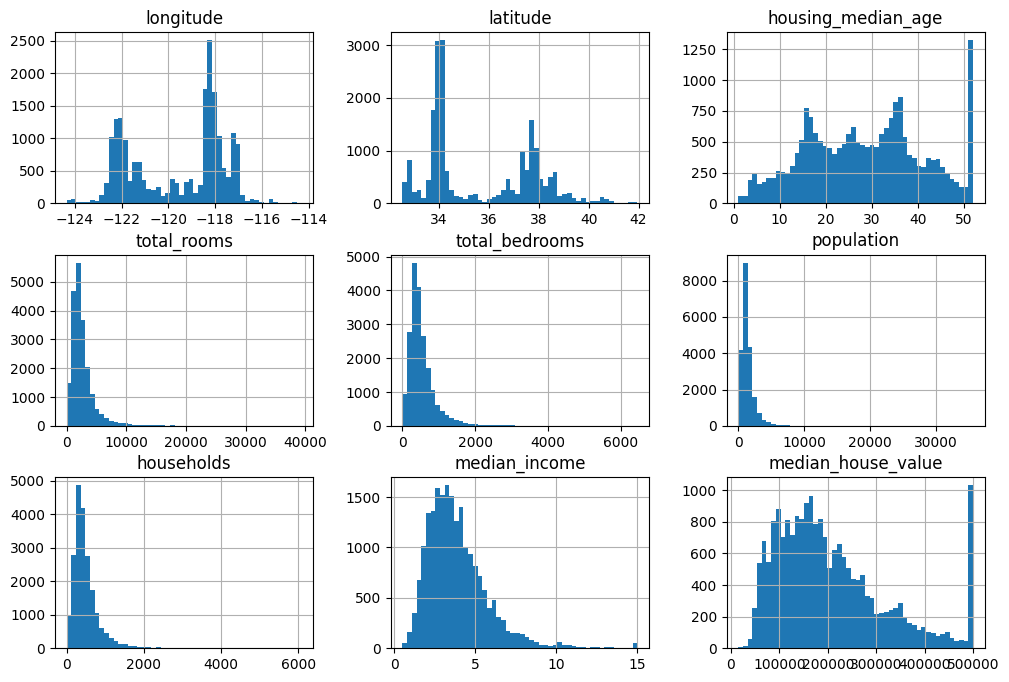

In [5]:
housing.describe()

housing.hist(bins=50, figsize=(12,8))
plt.show()

- We notice that median income is not expressed in USD - it has been scaled and capped at 15 for higher median incomes and 0.5 for lower median, with numbers representing roughly 10,000s of dollars

- Also the housing median age and median house value hae been capped, the latter may be a problem since it is our target attribute; our algorithm may learn that prices never go beyond that limit thus we won't be able to make predictions above $500,000

In [6]:
## Want put aside a test set of data that we are not going to look at until we have our model

### We do this by picking random instances (~ 20% of the dataset) and setting it aside

def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices] 

train_set, test_set = shuffle_and_split_data(housing, 0.2)



But if we run this again, it will generate a different test set, and over time we will see the whole data set, which is what we want to avoid...

To have a stable train/test split even after updating the dataset, a common solution is to use each instances identifier to decide whether or not it should go in the test set. E.g could compute a hash of each instance's identifier, and put that instance in the test set if the hash is lower than equal to 20% of the maximum hash value.

Thus everytime we split the data, the new test set will contain 20% of the new instances, but not any instance that was previously in the training set.

In [16]:
## Trying Scikit-Learn

from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing, test_size = 0.2, random_state=42)


We are told that median income is a very important attribute to predict median housing prices. We should want to ensure that the test set is representative of the various categories of incomes in the whole dataset.

Since median income is a continuous numerical attribute, we want to first create an income category attribute.

From the histogram we see that most median incomes are clustered from 1.5 ~ 6, but some go beyond 6. It is important to have a sufficient amount of instances in our dataset for each stratum, or the estimate of the stratum's importance may be biased.

Thus we shouldn't have too many strata, and each should be large enough

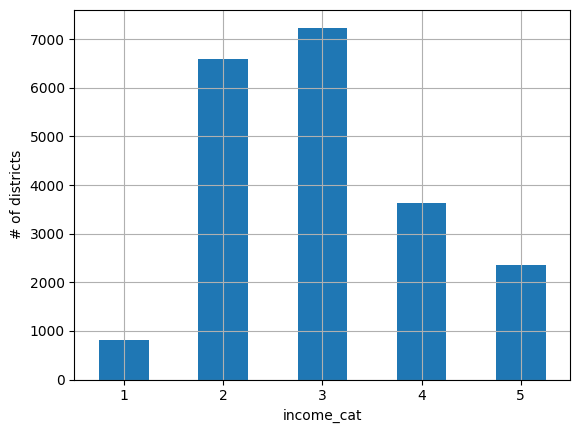

In [ ]:
## Use pd.cut function to create an income category attribute with five categories (labelled 1-5):

housing["income_cat"] = pd.cut(housing['median_income'], bins = [0., 1.5, 3.0, 4.5, 6.,np.inf], labels = [1, 2, 3, 4, 5])

## Looking at these:

housing['income_cat'].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.ylabel('# of districts)
plt.show()

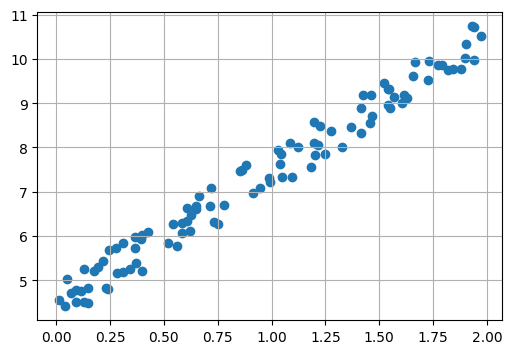

In [38]:
np.random.seed(42)

m= 100
X = 2 * np.random.rand(m,1)
y = 4 + 3 * X + np.random.rand(m,1)

plt.figure(figsize=(6,4))
plt.scatter(X, y)
plt.grid(True, which='both')
plt.show()

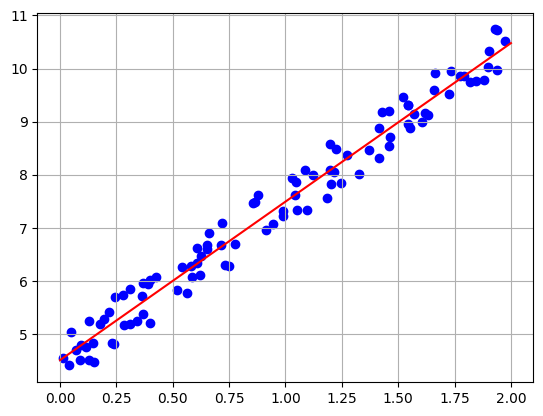

In [46]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)

y_predict = X_new_b @ theta_best

plt.figure()
plt.grid()
plt.plot(X_new, y_predict, color='red')
plt.scatter(X,y, color='blue')
plt.show()